In [1]:
from google.colab import drive
drive.mount("/content/gdrive", force_remount=True)

Mounted at /content/gdrive


In [2]:
# Vérifier que le GPU est disponible
import tensorflow as tf
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import keras
from keras.models import Sequential, load_model
from keras.layers import Dense, Conv2D, Flatten, Dropout, BatchNormalization, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ModelCheckpoint, CSVLogger
import tensorflow as tf
import pickle
from sklearn.metrics import classification_report, confusion_matrix

## Chargement et préparation des données

In [4]:
import shutil, os

# Copier les données de Drive vers /content/ (RAM/SSD local de Colab)
print('Copie en cours...')
shutil.copytree('/content/gdrive/My Drive/DL/train/', '/content/data/train/')
shutil.copytree('/content/gdrive/My Drive/DL/val/',   '/content/data/val/')
shutil.copytree('/content/gdrive/My Drive/DL/test/',  '/content/data/test/')
print('Copie terminée !')

Copie en cours...
Copie terminée !


In [5]:
#Séparation des datagens — augmentation pour train, rescale seul pour val/test
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.1
)
datagen_val_test = ImageDataGenerator(rescale=1./255)

In [19]:
#datagen_train pour train, datagen_val_test pour val et test
_train_gen_base = datagen_train.flow_from_directory(
    '/content/data/train/', target_size=(96, 96), class_mode='binary', batch_size=128)
_val_gen_base = datagen_val_test.flow_from_directory(
    '/content/data/val/', target_size=(96, 96), class_mode='binary', batch_size=128)
test = datagen_val_test.flow_from_directory(
    '/content/data/test/', target_size=(96, 96), class_mode='binary', batch_size=128, shuffle=False)

# Calcul des steps (à partir des generators de base, avant conversion tf.data)
STEP_SIZE_TRAIN = _train_gen_base.n // _train_gen_base.batch_size
STEP_SIZE_VAL   = _val_gen_base.n  // _val_gen_base.batch_size

print(f'Train: {_train_gen_base.n} images, {STEP_SIZE_TRAIN} steps/epoch')
print(f'Val  : {_val_gen_base.n} images, {STEP_SIZE_VAL} steps/epoch')
print(f'Test : {test.n} images')

Found 3816 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.
Train: 3816 images, 29 steps/epoch
Val  : 1908 images, 14 steps/epoch
Test : 1908 images


In [20]:
# Conversion en tf.data.Dataset répétable (nécessaire pour model.fit avec steps_per_epoch)
def create_repeatable_tf_dataset(generator_base):
    generator_base.reset()
    first_batch_imgs, first_batch_labels = next(generator_base)

    output_signature = (
        tf.TensorSpec(shape=first_batch_imgs.shape, dtype=tf.float32),
        tf.TensorSpec(shape=first_batch_labels.shape, dtype=tf.float32)
    )
    generator_base.reset()

    dataset = tf.data.Dataset.from_generator(
        lambda: generator_base,
        output_signature=output_signature
    )

    dataset = dataset.filter(
        lambda x, y: tf.equal(tf.shape(x)[0], first_batch_imgs.shape[0])
    )
    dataset = dataset.repeat()
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

In [24]:
import itertools

class InfiniteGenerator(tf.keras.utils.Sequence):
    """Wrapper qui rend un DirectoryIterator infini et ignore le dernier batch incomplet."""
    def __init__(self, directory_iterator):
        self.gen = directory_iterator
        self.batch_size = directory_iterator.batch_size
        self.steps = directory_iterator.n // directory_iterator.batch_size  # ignorer le dernier batch

    def __len__(self):
        return self.steps

    def __getitem__(self, idx):
        return self.gen[idx]

    def on_epoch_end(self):
        self.gen.on_epoch_end()

In [25]:
# Plus besoin de tf.data — utiliser directement les generators avec le wrapper
train = InfiniteGenerator(_train_gen_base)
val   = InfiniteGenerator(_val_gen_base)

STEP_SIZE_TRAIN = len(train)
STEP_SIZE_VAL   = len(val)

print(f'Train: {STEP_SIZE_TRAIN} steps/epoch')
print(f'Val  : {STEP_SIZE_VAL} steps/epoch')

Train: 29 steps/epoch
Val  : 14 steps/epoch


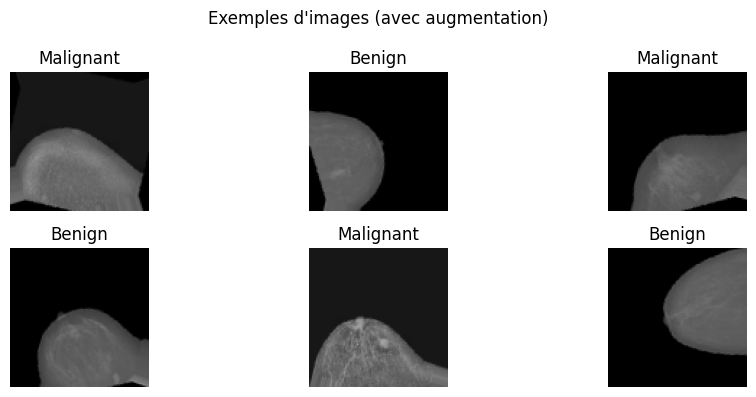

In [21]:
imgs, labels = next(_train_gen_base)
plt.figure(figsize=(10,4))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(imgs[i])
    plt.title('Malignant' if labels[i]==1 else 'Benign')
    plt.axis('off')
plt.suptitle('Exemples d\'images (avec augmentation)')
plt.tight_layout()
plt.show()

## Modèle 1 — CNN from scratch

In [26]:
from keras.layers import Input

model = Sequential([
    Input(shape=(96, 96, 3)),  #Input layer explicite
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 45, 45, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 438,369 (1.67 MB)

 Trainable params: 438,369 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
csv_logger   = CSVLogger('/content/gdrive/My Drive/DL/training.log', separator=',', append=False)
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint_cnn = ModelCheckpoint('/content/gdrive/My Drive/DL/best_cnn.keras',
                                  monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)

history = model.fit(
    train,
    validation_data=val,
    epochs=50,
    callbacks=[csv_logger, early_stopping, checkpoint_cnn]
)
model.save('/content/gdrive/My Drive/DL/first_model.keras')

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.6553 - loss: 0.6575
Epoch 1: val_accuracy improved from None to 0.66574, saving model to /content/gdrive/My Drive/DL/best_cnn.keras

Epoch 1: finished saving model to /content/gdrive/My Drive/DL/best_cnn.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 18s 485ms/step - accuracy: 0.6668 - loss: 0.6460 - val_accuracy: 0.6657 - val_loss: 0.6383
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - accuracy: 0.6788 - loss: 0.6338
Epoch 2: val_accuracy improved from 0.66574 to 0.67020, saving model to /content/gdrive/My Drive/DL/best_cnn.keras

Epoch 2: finished saving model to /content/gdrive/My Drive/DL/best_cnn.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 13s 453ms/step - accuracy: 0.6708 - loss: 0.6378 - val_accuracy: 0.6702 - val_loss: 0.6316
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.6665 - loss: 0.6420
Epoch 3: val_accuracy did not improve from 0.67020
29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 462ms/step - accuracy: 0.6668 - loss: 0.6

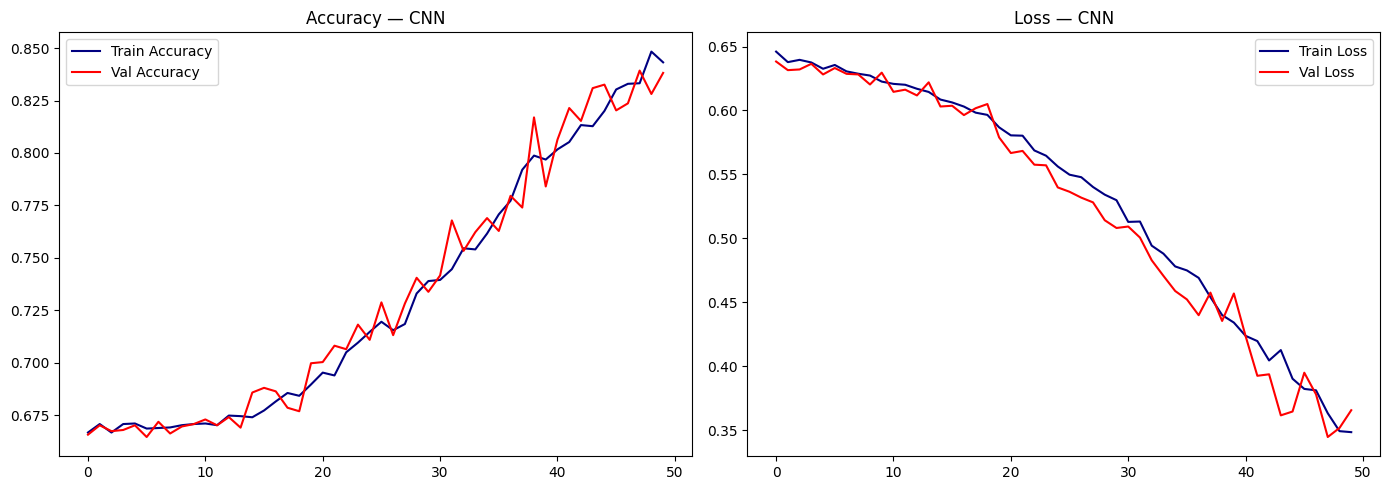

In [28]:
# Courbes d'apprentissage — CNN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'],     label='Train Accuracy', color='navy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy',   color='red')
ax1.set_title('Accuracy — CNN'); ax1.legend()

ax2.plot(history.history['loss'],     label='Train Loss', color='navy')
ax2.plot(history.history['val_loss'], label='Val Loss',   color='red')
ax2.set_title('Loss — CNN'); ax2.legend()

plt.tight_layout(); plt.show()

In [29]:
# Extraction du test set (une seule fois, réutilisé par tous les modèles)
steps = test.n // test.batch_size
test.reset()
X_test, y_test = [], []
for i in range(steps):
    a, b = next(test)
    X_test.extend(a)
    y_test.extend(b)
X_test, y_test = np.array(X_test), np.array(y_test)
print(f'Test set: {X_test.shape}, labels: {y_test.shape}')

pickle.dump(X_test, open('/content/gdrive/My Drive/DL/X_test.pkl', 'wb'))
pickle.dump(y_test, open('/content/gdrive/My Drive/DL/y_test.pkl', 'wb'))

Test set: (1792, 96, 96, 3), labels: (1792,)


In [30]:
def evaluate_model(model_obj, X, y, model_name='Modèle'):
    """Évalue un modèle et affiche confusion matrix + rapport."""
    score = model_obj.evaluate(X, y, verbose=0)
    print(f'[{model_name}] Test loss: {score[0]:.4f} | Test accuracy: {score[1]:.4f}')

    y_prob = model_obj.predict(X)
    y_pred = np.where(y_prob > 0.5, 1, 0)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(confusion_matrix(y, y_pred), ax=axes[0],
                cmap=plt.cm.Blues, annot=True, annot_kws={'size': 20}, fmt='g')
    axes[0].set_xticklabels(['Malignant', 'Benign'], fontsize=12)
    axes[0].set_yticklabels(['Malignant', 'Benign'], fontsize=12)
    axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
    axes[0].set_title(f'Confusion Matrix — {model_name}')

    fpr, tpr, _ = __import__('sklearn.metrics', fromlist=['roc_curve','auc']).roc_curve(y, y_prob)
    auc_val = __import__('sklearn.metrics', fromlist=['auc']).auc(fpr, tpr)
    axes[1].plot([0,1],[0,1],'r--')
    axes[1].plot(fpr, tpr, label=f'AUC = {auc_val:.3f}')
    axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
    axes[1].set_title(f'ROC Curve — {model_name}'); axes[1].legend()

    plt.tight_layout(); plt.show()
    print(classification_report(y, y_pred, target_names=['Benign (Class 0)', 'Malignant (Class 1)']))
    return y_prob, y_pred

[CNN from scratch] Test loss: 0.3683 | Test accuracy: 0.8426
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


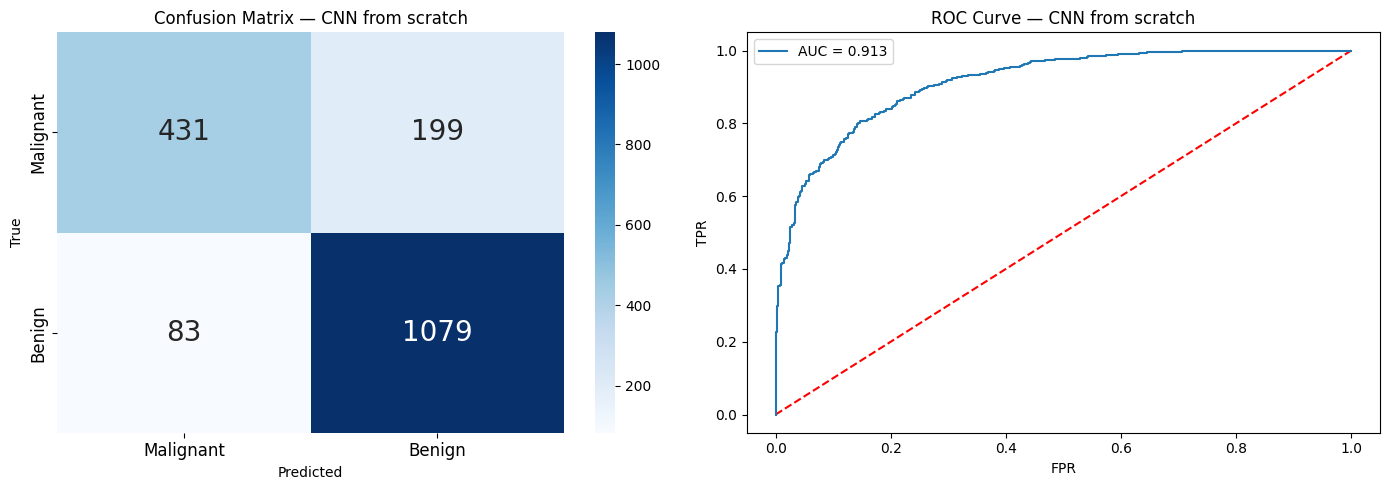

                     precision    recall  f1-score   support

   Benign (Class 0)       0.84      0.68      0.75       630
Malignant (Class 1)       0.84      0.93      0.88      1162

           accuracy                           0.84      1792
          macro avg       0.84      0.81      0.82      1792
       weighted avg       0.84      0.84      0.84      1792



In [31]:
y_prob_cnn, y_pred_cnn = evaluate_model(model, X_test, y_test, 'CNN from scratch')

## Transfer Learning — VGG16 (Feature Extraction)

In [32]:
#preprocess_input pour VGG16
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input as vgg_preprocess

# Regénérer les generators avec le bon preprocessing VGG16
datagen_vgg = ImageDataGenerator(preprocessing_function=vgg_preprocess)

_train_vgg = datagen_vgg.flow_from_directory(
    '/content/data/train/', target_size=(96,96), class_mode='binary', batch_size=128)
_val_vgg = datagen_vgg.flow_from_directory(
    '/content/data/val/', target_size=(96,96), class_mode='binary', batch_size=128)

train_vgg = create_repeatable_tf_dataset(_train_vgg)
val_vgg   = create_repeatable_tf_dataset(_val_vgg)

STEP_TRAIN_VGG = _train_vgg.n // _train_vgg.batch_size
STEP_VAL_VGG   = _val_vgg.n  // _val_vgg.batch_size

Found 3816 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.


In [35]:
train_vgg = InfiniteGenerator(_train_vgg)
val_vgg   = InfiniteGenerator(_val_vgg)

STEP_TRAIN_VGG = len(train_vgg)
STEP_VAL_VGG   = len(val_vgg)

In [36]:
backbone = VGG16(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
backbone.trainable = False

VGG_model = Sequential([
    backbone,
    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

VGG_model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    metrics=['accuracy']
)
VGG_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,077,057 (65.14 MB)

 Trainable params: 2,361,345 (9.01 MB)

 Non-trainable params: 14,715,712 (56.14 MB)

In [37]:
checkpoint_vgg = ModelCheckpoint('/content/gdrive/My Drive/DL/best_vgg.keras',
                                  monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping_vgg = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_vgg = VGG_model.fit(
    train_vgg,
    validation_data=val_vgg,
    epochs=50,
    callbacks=[early_stopping_vgg, checkpoint_vgg]
)
VGG_model.save('/content/gdrive/My Drive/DL/VGG_model.keras')

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.5187 - loss: 0.9848
Epoch 1: val_accuracy improved from None to 0.69810, saving model to /content/gdrive/My Drive/DL/best_vgg.keras

Epoch 1: finished saving model to /content/gdrive/My Drive/DL/best_vgg.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 329ms/step - accuracy: 0.5315 - loss: 0.9445 - val_accuracy: 0.6981 - val_loss: 0.6722
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.6094 - loss: 0.7486
Epoch 2: val_accuracy improved from 0.69810 to 0.73828, saving model to /content/gdrive/My Drive/DL/best_vgg.keras

Epoch 2: finished saving model to /content/gdrive/My Drive/DL/best_vgg.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 260ms/step - accuracy: 0.6048 - loss: 0.7622 - val_accuracy: 0.7383 - val_loss: 0.5355
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.6675 - loss: 0.6432
Epoch 3: val_accuracy improved from 0.73828 to 0.76674, saving model to /content/gdrive/My Drive/DL/best_vgg.keras

Epoch 3:

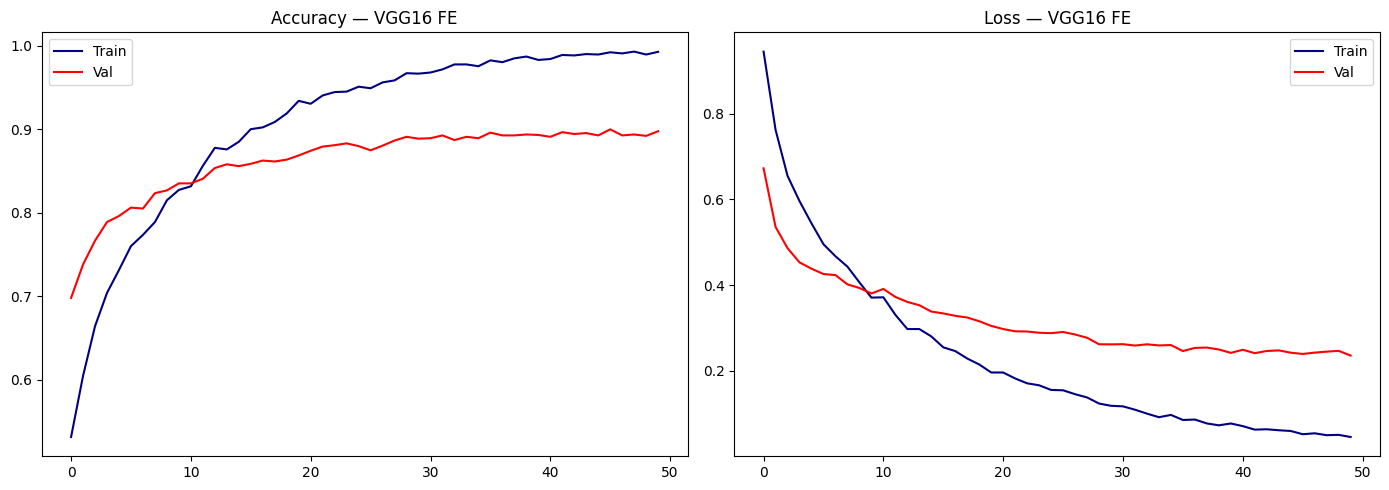

In [38]:
# Courbes VGG16 Feature Extraction
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history_vgg.history['accuracy'],     label='Train', color='navy')
ax1.plot(history_vgg.history['val_accuracy'], label='Val',   color='red')
ax1.set_title('Accuracy — VGG16 FE'); ax1.legend()
ax2.plot(history_vgg.history['loss'],     label='Train', color='navy')
ax2.plot(history_vgg.history['val_loss'], label='Val',   color='red')
ax2.set_title('Loss — VGG16 FE'); ax2.legend()
plt.tight_layout(); plt.show()

Found 1908 images belonging to 2 classes.
[VGG16 Feature Extraction] Test loss: 0.2362 | Test accuracy: 0.9012
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step


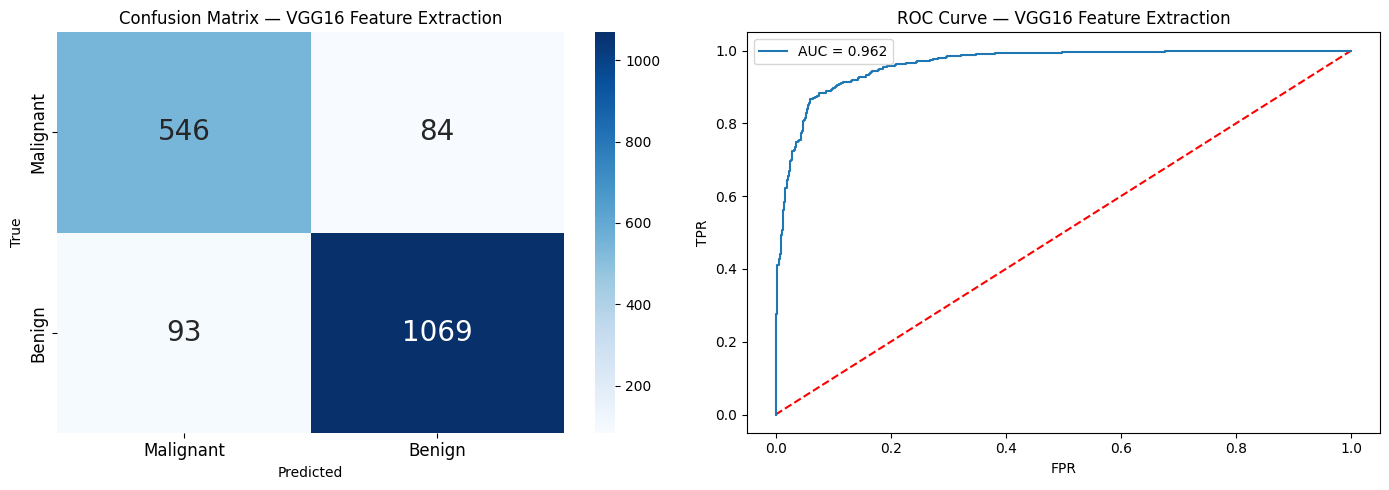

                     precision    recall  f1-score   support

   Benign (Class 0)       0.85      0.87      0.86       630
Malignant (Class 1)       0.93      0.92      0.92      1162

           accuracy                           0.90      1792
          macro avg       0.89      0.89      0.89      1792
       weighted avg       0.90      0.90      0.90      1792



In [39]:
# ✅ Evaluer avec le preprocessing VGG16 sur X_test
test_vgg = datagen_vgg.flow_from_directory(
    '/content/data/test/', target_size=(96,96), class_mode='binary', batch_size=128, shuffle=False)
steps_test = test_vgg.n // test_vgg.batch_size
test_vgg.reset()
X_test_vgg, y_test_vgg = [], []
for _ in range(steps_test):
    a, b = next(test_vgg)
    X_test_vgg.extend(a); y_test_vgg.extend(b)
X_test_vgg, y_test_vgg = np.array(X_test_vgg), np.array(y_test_vgg)

y_prob_vgg, y_pred_vgg = evaluate_model(VGG_model, X_test_vgg, y_test_vgg, 'VGG16 Feature Extraction')

## Transfer Learning — VGG16 (Fine Tuning)

In [40]:
backbone2 = VGG16(input_shape=(96, 96, 3), include_top=False, weights='imagenet')

#Dégeler les 2 derniers blocs de convolution sur backbone2
for layer in backbone2.layers:
    layer.trainable = layer.name >= 'block4_conv1'  # Dégeler block4 et block5

# Afficher quelles couches sont entraînables
for layer in backbone2.layers:
    print(f'{layer.name:25s} trainable={layer.trainable}')

input_layer_8             trainable=True
block1_conv1              trainable=False
block1_conv2              trainable=False
block1_pool               trainable=False
block2_conv1              trainable=False
block2_conv2              trainable=False
block2_pool               trainable=False
block3_conv1              trainable=False
block3_conv2              trainable=False
block3_conv3              trainable=False
block3_pool               trainable=False
block4_conv1              trainable=True
block4_conv2              trainable=True
block4_conv3              trainable=True
block4_pool               trainable=True
block5_conv1              trainable=True
block5_conv2              trainable=True
block5_conv3              trainable=True
block5_pool               trainable=True


In [41]:
VGG_model_2 = Sequential([
    backbone2,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

#Learning rate plus faible pour le fine-tuning
VGG_model_2.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    metrics=['accuracy']
)
VGG_model_2.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,249 (56.14 MB)

 Trainable params: 12,980,737 (49.52 MB)

 Non-trainable params: 1,736,512 (6.62 MB)

In [42]:
checkpoint_vgg2 = ModelCheckpoint('/content/gdrive/My Drive/DL/best_vgg2.keras',
                                   monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping_vgg2 = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_vgg2 = VGG_model_2.fit(
    train_vgg,
    validation_data=val_vgg,
    epochs=50,
    callbacks=[early_stopping_vgg2, checkpoint_vgg2]
)
VGG_model_2.save('/content/gdrive/My Drive/DL/VGG_model_2.keras')

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.5184 - loss: 0.9240
Epoch 1: val_accuracy improved from None to 0.60491, saving model to /content/gdrive/My Drive/DL/best_vgg2.keras

Epoch 1: finished saving model to /content/gdrive/My Drive/DL/best_vgg2.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 26s 403ms/step - accuracy: 0.5331 - loss: 0.8944 - val_accuracy: 0.6049 - val_loss: 0.7090
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.6257 - loss: 0.7276
Epoch 2: val_accuracy improved from 0.60491 to 0.63839, saving model to /content/gdrive/My Drive/DL/best_vgg2.keras

Epoch 2: finished saving model to /content/gdrive/My Drive/DL/best_vgg2.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 339ms/step - accuracy: 0.6185 - loss: 0.7145 - val_accuracy: 0.6384 - val_loss: 0.6456
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.6638 - loss: 0.6312
Epoch 3: val_accuracy improved from 0.63839 to 0.73996, saving model to /content/gdrive/My Drive/DL/best_vgg2.keras

Ep

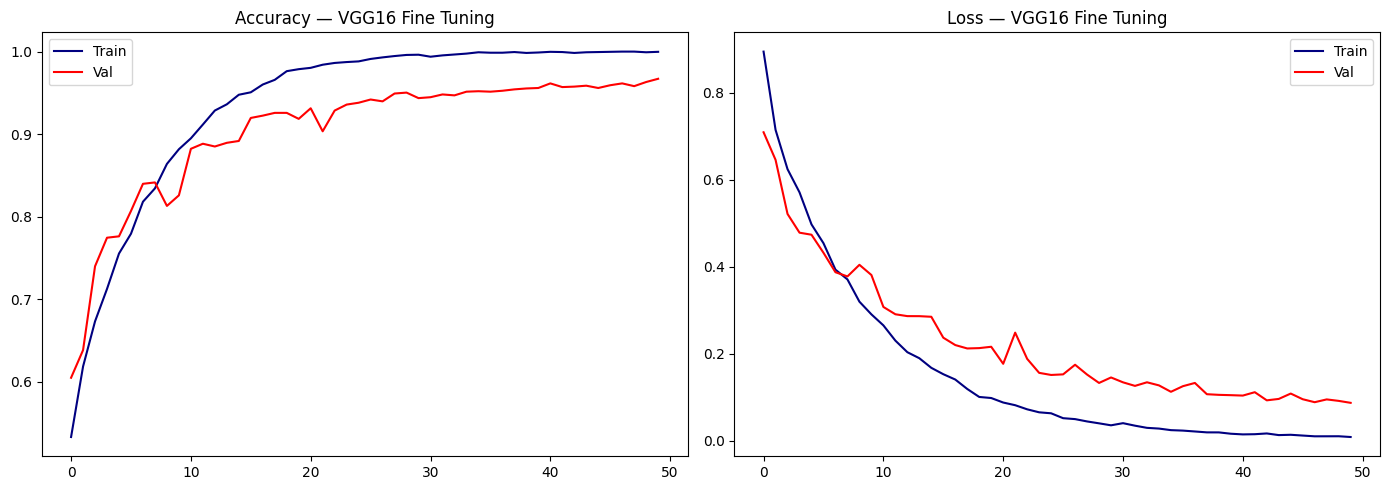

In [43]:
# Courbes VGG16 Fine Tuning
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history_vgg2.history['accuracy'],     label='Train', color='navy')
ax1.plot(history_vgg2.history['val_accuracy'], label='Val',   color='red')
ax1.set_title('Accuracy — VGG16 Fine Tuning'); ax1.legend()
ax2.plot(history_vgg2.history['loss'],     label='Train', color='navy')
ax2.plot(history_vgg2.history['val_loss'], label='Val',   color='red')
ax2.set_title('Loss — VGG16 Fine Tuning'); ax2.legend()
plt.tight_layout(); plt.show()

[VGG16 Fine Tuning] Test loss: 0.1035 | Test accuracy: 0.9643
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step


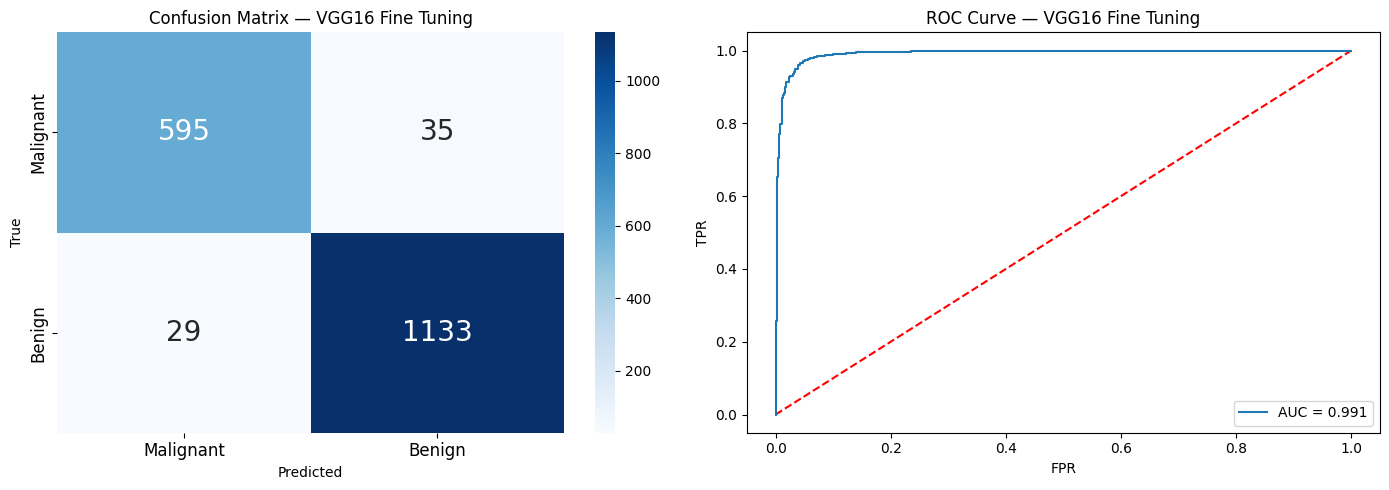

                     precision    recall  f1-score   support

   Benign (Class 0)       0.95      0.94      0.95       630
Malignant (Class 1)       0.97      0.98      0.97      1162

           accuracy                           0.96      1792
          macro avg       0.96      0.96      0.96      1792
       weighted avg       0.96      0.96      0.96      1792



In [44]:
y_prob_vgg2, y_pred_vgg2 = evaluate_model(VGG_model_2, X_test_vgg, y_test_vgg, 'VGG16 Fine Tuning')

## Transfer Learning — ResNet50

In [45]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess

datagen_resnet = ImageDataGenerator(preprocessing_function=resnet_preprocess)

_train_resnet = datagen_resnet.flow_from_directory(
    '/content/data/train/', target_size=(96,96), class_mode='binary', batch_size=128)
_val_resnet = datagen_resnet.flow_from_directory(
    '/content/data/val/', target_size=(96,96), class_mode='binary', batch_size=128)

train_resnet = InfiniteGenerator(_train_resnet)
val_resnet   = InfiniteGenerator(_val_resnet)

STEP_TRAIN_RN = len(train_resnet)
STEP_VAL_RN   = len(val_resnet)

Found 3816 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.


In [46]:
backbone3 = ResNet50(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
backbone3.trainable = False

ResNet50_model = Sequential([
    backbone3,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

ResNet50_model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    metrics=['accuracy']
)
ResNet50_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,953 (90.02 MB)

 Trainable params: 6,145 (24.00 KB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [47]:
checkpoint_rn = ModelCheckpoint('/content/gdrive/My Drive/DL/best_resnet.keras',
                                 monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping_rn = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_rn = ResNet50_model.fit(
    train_resnet,
    validation_data=val_resnet,
    epochs=50,
    callbacks=[early_stopping_rn, checkpoint_rn]
)
ResNet50_model.save('/content/gdrive/My Drive/DL/ResNet50_model.keras')

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.5379 - loss: 0.9517
Epoch 1: val_accuracy improved from None to 0.61328, saving model to /content/gdrive/My Drive/DL/best_resnet.keras

Epoch 1: finished saving model to /content/gdrive/My Drive/DL/best_resnet.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 28s 409ms/step - accuracy: 0.5240 - loss: 0.9682 - val_accuracy: 0.6133 - val_loss: 0.7381
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5382 - loss: 0.9278
Epoch 2: val_accuracy did not improve from 0.61328
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 239ms/step - accuracy: 0.5383 - loss: 0.9220 - val_accuracy: 0.6071 - val_loss: 0.7124
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5340 - loss: 0.9230
Epoch 3: val_accuracy improved from 0.61328 to 0.61384, saving model to /content/gdrive/My Drive/DL/best_resnet.keras

Epoch 3: finished saving model to /content/gdrive/My Drive/DL/best_resnet.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 257ms/step - accuracy: 0.5469 -

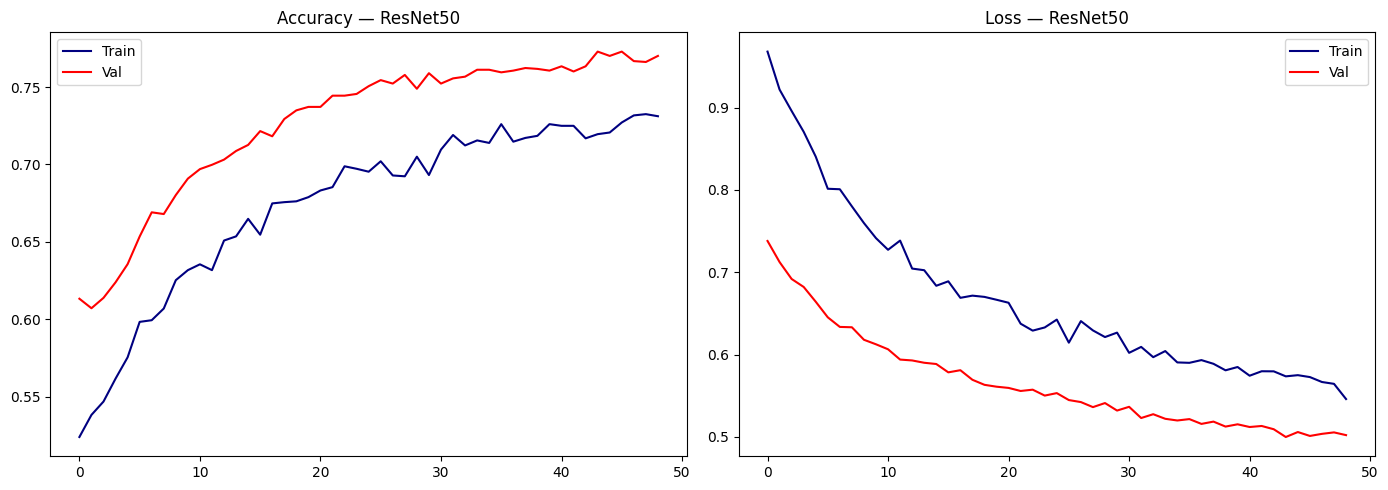

In [48]:
# Courbes ResNet50
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history_rn.history['accuracy'],     label='Train', color='navy')
ax1.plot(history_rn.history['val_accuracy'], label='Val',   color='red')
ax1.set_title('Accuracy — ResNet50'); ax1.legend()
ax2.plot(history_rn.history['loss'],     label='Train', color='navy')
ax2.plot(history_rn.history['val_loss'], label='Val',   color='red')
ax2.set_title('Loss — ResNet50'); ax2.legend()
plt.tight_layout(); plt.show()

Found 1908 images belonging to 2 classes.
[ResNet50] Test loss: 0.4994 | Test accuracy: 0.7556
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step


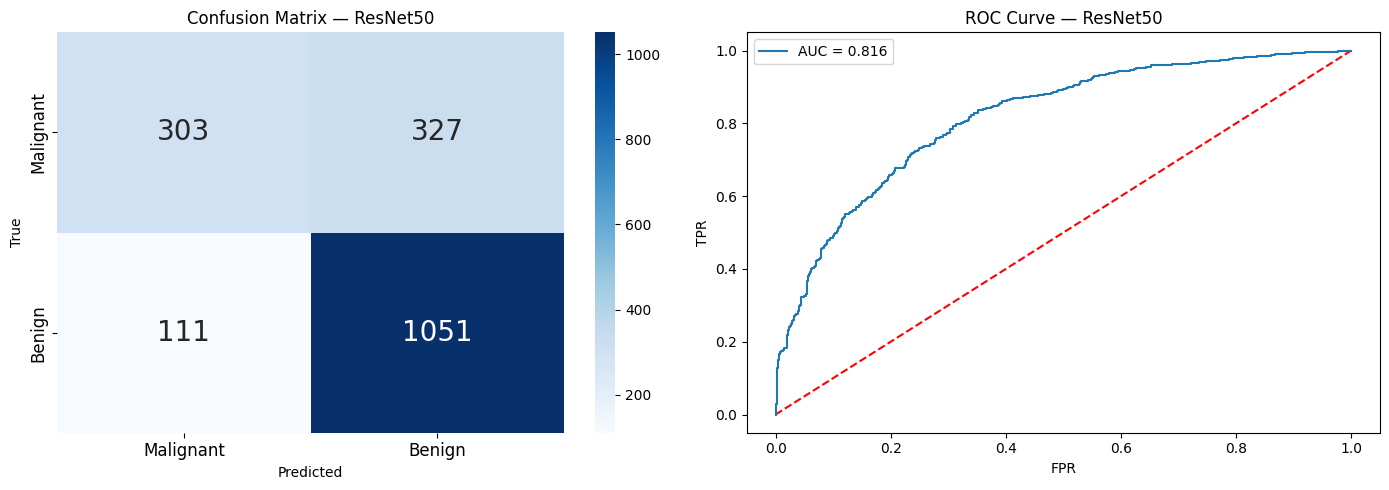

                     precision    recall  f1-score   support

   Benign (Class 0)       0.73      0.48      0.58       630
Malignant (Class 1)       0.76      0.90      0.83      1162

           accuracy                           0.76      1792
          macro avg       0.75      0.69      0.70      1792
       weighted avg       0.75      0.76      0.74      1792



In [49]:
# Extraction test set avec preprocessing ResNet
test_resnet = datagen_resnet.flow_from_directory(
    '/content/data/test/', target_size=(96,96), class_mode='binary', batch_size=128, shuffle=False)
steps_test_rn = test_resnet.n // test_resnet.batch_size
test_resnet.reset()
X_test_rn, y_test_rn = [], []
for _ in range(steps_test_rn):
    a, b = next(test_resnet)
    X_test_rn.extend(a); y_test_rn.extend(b)
X_test_rn, y_test_rn = np.array(X_test_rn), np.array(y_test_rn)

y_prob_rn, y_pred_rn = evaluate_model(ResNet50_model, X_test_rn, y_test_rn, 'ResNet50')

## Comparaison des modèles

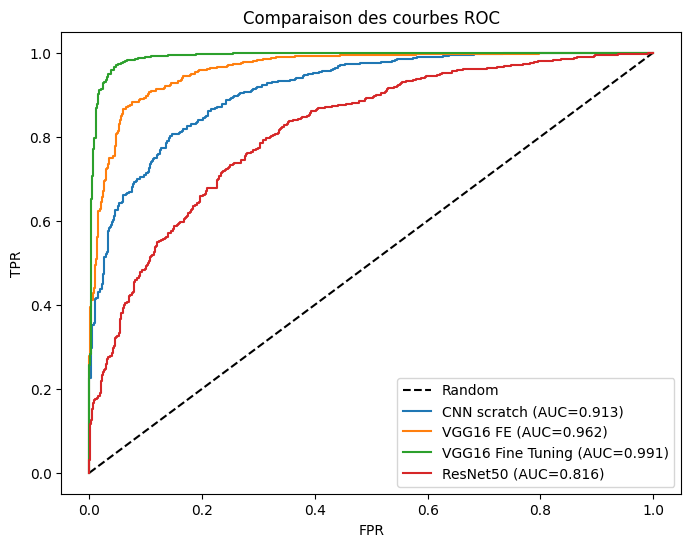


=== Résumé des performances ===
CNN scratch               | Accuracy=0.843 | F1=0.884 | AUC=0.913
VGG16 FE                  | Accuracy=0.901 | F1=0.924 | AUC=0.962
VGG16 Fine Tuning         | Accuracy=0.964 | F1=0.973 | AUC=0.991
ResNet50                  | Accuracy=0.756 | F1=0.828 | AUC=0.816


In [50]:
from sklearn.metrics import roc_curve, auc

models_info = [
    ('CNN scratch',         y_prob_cnn,  y_test,     y_pred_cnn),
    ('VGG16 FE',            y_prob_vgg,  y_test_vgg, y_pred_vgg),
    ('VGG16 Fine Tuning',   y_prob_vgg2, y_test_vgg, y_pred_vgg2),
    ('ResNet50',            y_prob_rn,   y_test_rn,  y_pred_rn),
]

plt.figure(figsize=(8,6))
plt.plot([0,1],[0,1],'k--', label='Random')
for name, prob, ytrue, _ in models_info:
    fpr, tpr, _ = roc_curve(ytrue, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc(fpr,tpr):.3f})')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('Comparaison des courbes ROC')
plt.legend(loc='lower right')
plt.show()

print('\n=== Résumé des performances ===')
from sklearn.metrics import accuracy_score, f1_score
for name, prob, ytrue, ypred in models_info:
    acc = accuracy_score(ytrue, ypred)
    f1  = f1_score(ytrue, ypred)
    fpr, tpr, _ = roc_curve(ytrue, prob)
    auc_val = auc(fpr, tpr)
    print(f'{name:25s} | Accuracy={acc:.3f} | F1={f1:.3f} | AUC={auc_val:.3f}')